In [85]:
import numpy as np
import matplotlib.pyplot as plt
import math
np.random.seed(3)

In [ ]:
#Valores diferentes de T para analisar o seu efeito
valores_t = [ 0.1, 0.5, 1 , 5, 10, 50]

In [ ]:
#Gerando um valor Zk da Normal 

def Normal(mi,sigma2):
    u = np.random.uniform()
    u_2pi = 2*np.pi*u
    t = -np.log(u)
    x = np.sqrt(2*t)*np.cos(u_2pi)

    return np.sqrt(sigma2)*x + mi


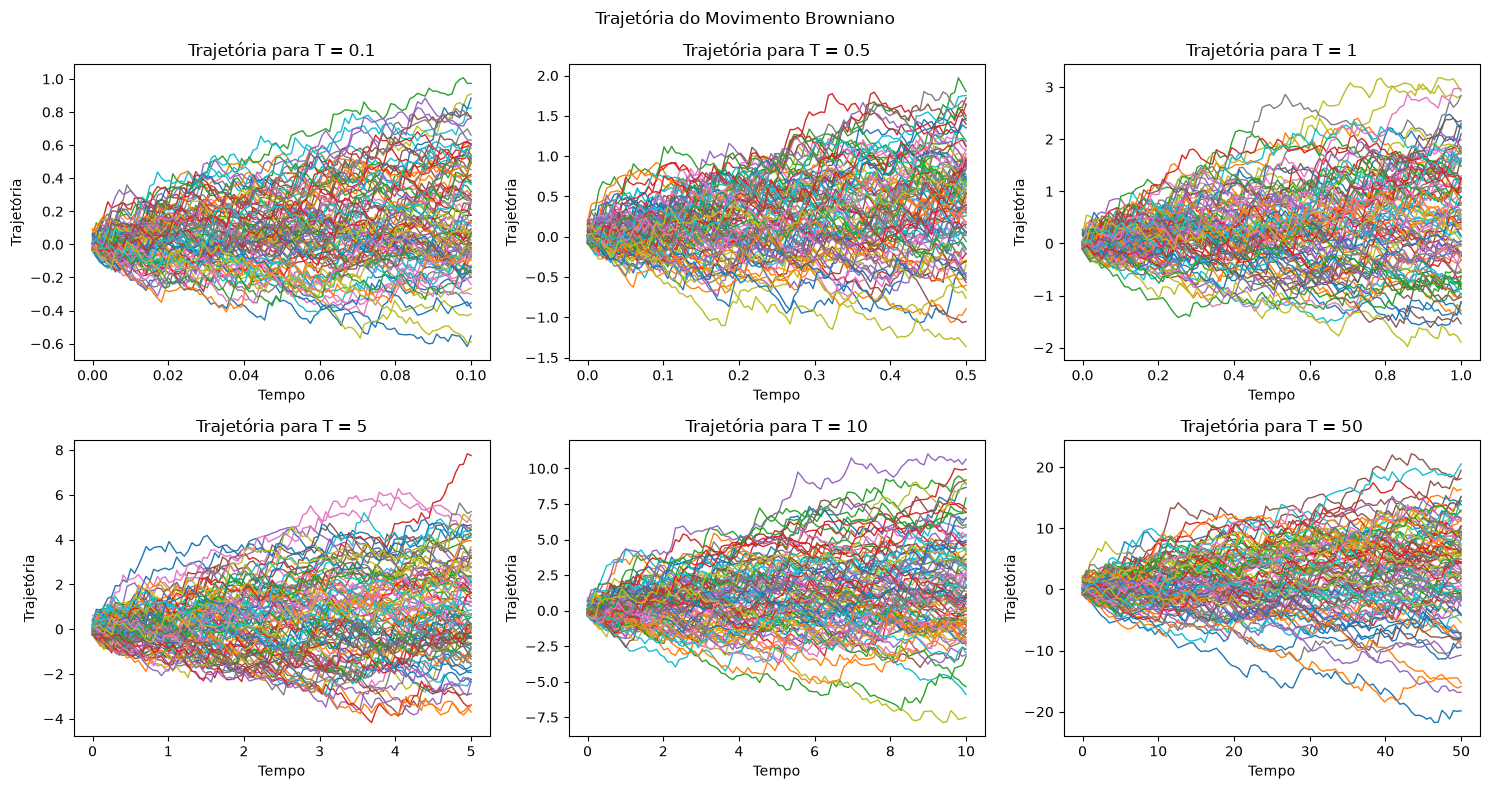

In [88]:
plt.figure(figsize=(15,8))
posicao = 1

for t in valores_t:
    plt.subplot(2,3,posicao)
    posicao += 1

    n = 100
    dt = t/n
    time = np.linspace(0,t,n)

    simulacoes = 100
    todas_trajetorias = []
    for i in range(simulacoes):
        x = 0
        trajetoria = []

        for k in range(n):
            x = x + np.sqrt(dt)*Normal(0,1)
            trajetoria.append(x)
        todas_trajetorias.append(trajetoria)
    for j in range(simulacoes):
        plt.plot(time, todas_trajetorias[j], linewidth = 1)


    plt.xlabel('Tempo')
    plt.ylabel('Trajetória')
    plt.title(f'Trajetória para T = {t}')
plt.suptitle('Trajetória do Movimento Browniano')
plt.tight_layout()
plt.show()

In [ ]:
#Função densidade da Normal
def normal(x,mi,sigma2):
    num = np.exp(-(x-mi)**2/(2*sigma2))
    den = np.sqrt(2*sigma2*np.pi)
    return num/den

In [ ]:
#Parâmetros do item b
def p(x):
    return normal(x,-2,1)/2 + normal(x,2,1)/2

def a(x):
    return -x+ 2*math.tanh(2*x)


b = np.sqrt(2)


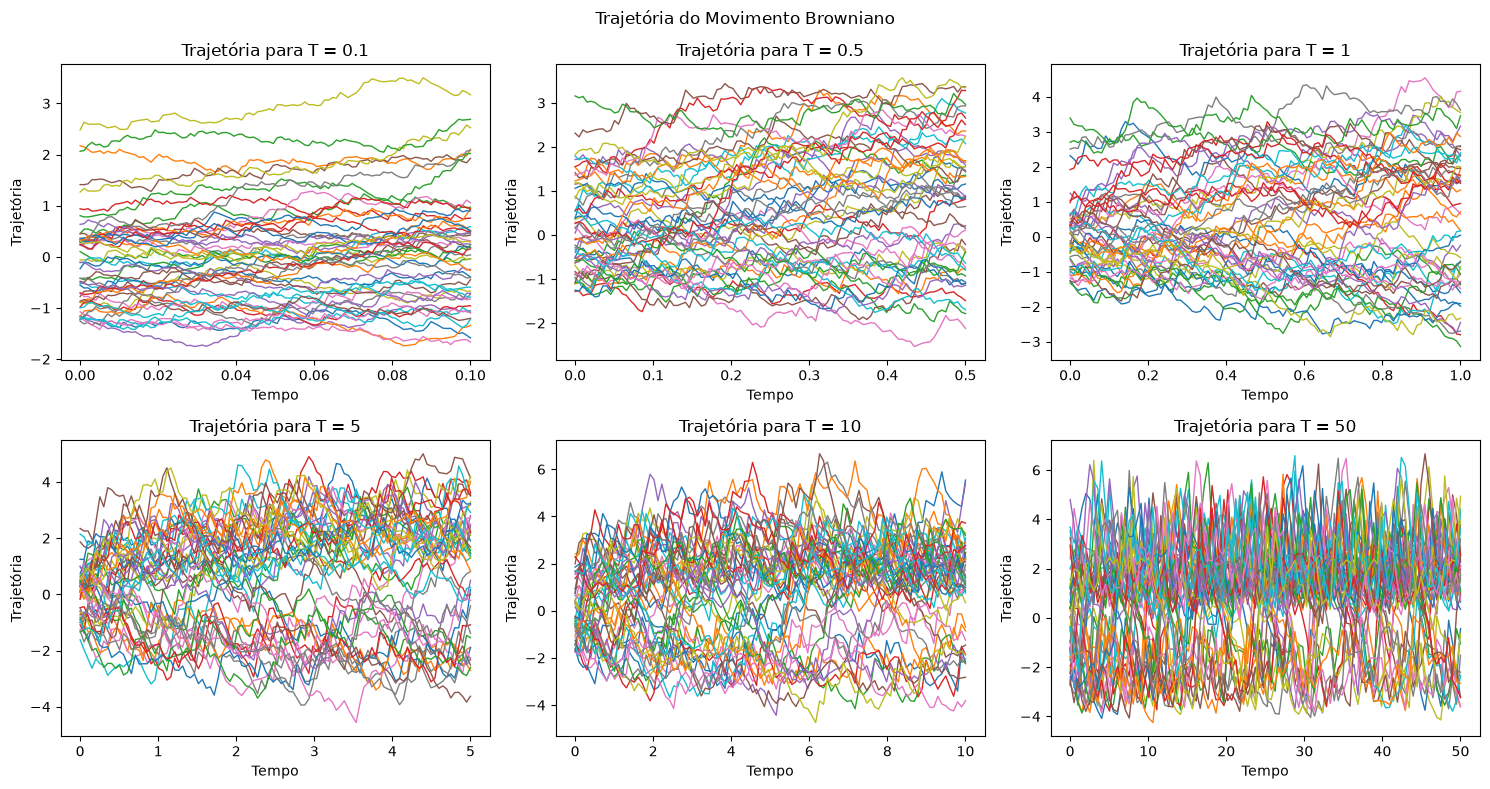

In [91]:
plt.figure(figsize=(15,8))
posicao = 1
todos_valores_finais = []

for t in valores_t:
    plt.subplot(2,3,posicao)
    posicao += 1
    n = 100
    dt = t/n
    time = np.linspace(0,t,n)

    simulacoes = 1000
    valores_finais = []
    trajetorias_finais = []
    for i in range(simulacoes):
        x = Normal(0,1)
        trajetoria = []
        #Atualização da trajetoria e memorização de cada passo
        for k in range(n):
            x = x + b*np.sqrt(dt)*Normal(0,1) + a(x)*dt
            trajetoria.append(x)
        valores_finais.append(x)
        trajetorias_finais.append(trajetoria)

    todos_valores_finais.append(valores_finais)
    for j in range(50):
        plt.plot(time, trajetorias_finais[j], linewidth = 1)

    plt.xlabel('Tempo')
    plt.ylabel('Trajetória')
    plt.title(f'Trajetória para T = {t}')
    
plt.suptitle('Trajetória do Movimento Browniano')
plt.tight_layout()
plt.show()

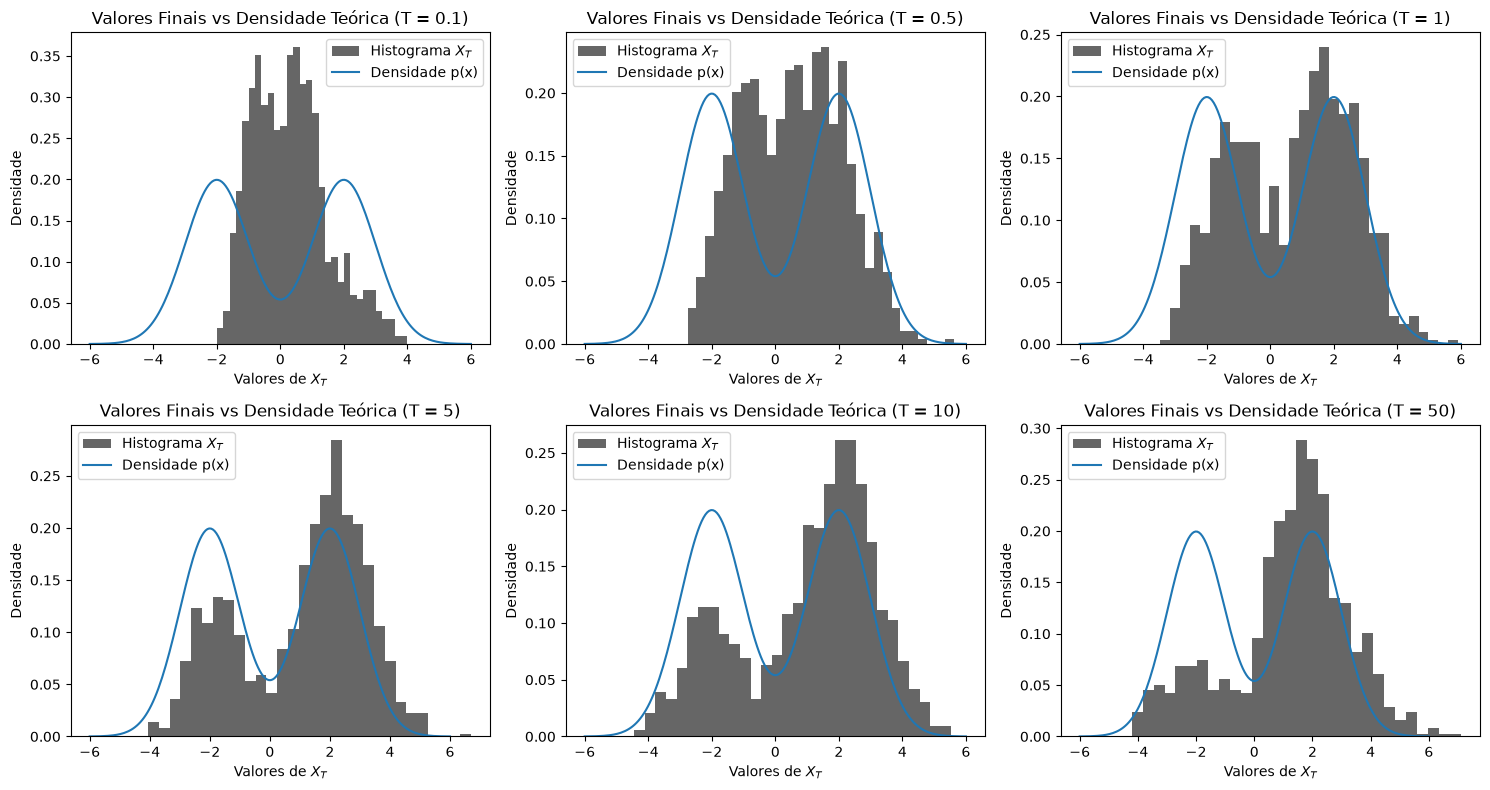

In [92]:
#Plotando Histogramas de Xt e p(x)
eixo_x = np.linspace(-6, 6, 200)
plt.figure(figsize=(15, 8))
posicao = 1

for idx in range(len(valores_t)):
    plt.subplot(2, 3, posicao)
    posicao += 1

    plt.hist(todos_valores_finais[idx], bins=30, density=True, alpha=0.6, color='black', label='Histograma $X_T$')
    plt.plot(eixo_x, p(eixo_x),label='Densidade p(x)')

    plt.xlabel('Valores de $X_T$')
    plt.ylabel('Densidade')
    plt.title(f'Valores Finais vs Densidade Teórica (T = {valores_t[idx]})')
    plt.legend()

plt.tight_layout()
plt.show()

Discursões

1.Faz com que as trajetórias comecem espalhadas diferentemente do caso de a = 0, onde todas começavam na mesma região. Além disso, atua como um fator de impedimento do crescimento indefinido da variância, convergindo para valores em torno de -4 e 4.

2.Com a redução do passo $\Delta t$ há uma diminuição na distorção das trajetórias, além disso os histogramas tambem evidenciam esse comportamento mais estavel, ou seja, com a diminuição do achatamento do picos e da assimetria entre eles.

3.Para valores tempos pequenos T=0.1 e T=0.5 as partículas ainda não tiveram tempo suficiente para se mover de forma significativa, por isso os histogramas refletem a condição inicial $X_0 \sim \mathcal{N}(0, 1)$ . Quando o valor de T aumenta para T=1 e T=5, por exemplo, a partícula possui tempo suficente para atingir a distribuição de p(x).